# FleetLogix · Avance 1 — Análisis del modelo y generación de datos sintéticos

**Proyecto Integrador M2 · Data Science** — Laura Garmendia

FleetLogix opera 200 vehículos que hacen entregas de última milla en 5 ciudades de Colombia. Recibimos una base PostgreSQL con 6 tablas vacías. En este avance:

1. **Analizamos el modelo relacional**: relaciones, constraints, patrones de negocio implícitos y mejoras posibles, con el diagrama ER.
2. **Poblamos las 6 tablas con 505.650 registros sintéticos** coherentes (`2. Scripts/01_data_generation.py`).
3. **Controlamos la calidad**: integridad referencial, consistencia temporal, reglas de negocio, distribuciones y logs de carga.

| Tabla | Tipo | Registros |
|---|---|---:|
| vehicles | maestra | 200 |
| drivers | maestra | 400 |
| routes | maestra | 50 |
| trips | transaccional | 100.000 |
| deliveries | transaccional | 400.000 |
| maintenance | transaccional | 5.000 |
| **Total** | | **505.650** |

**Requisitos:** PostgreSQL 15+ con la base `fleetlogix` creada con `fleetlogix_db_schema.sql`, y `pip install psycopg2-binary pandas numpy faker matplotlib`.

In [1]:
%pip install psycopg2-binary faker pandas numpy matplotlib

  Using cached psycopg2_binary-2.9.13-cp314-cp314-macosx_11_0_arm64.whl.metadata (4.9 kB)
Using cached psycopg2_binary-2.9.13-cp314-cp314-macosx_11_0_arm64.whl (3.8 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 38.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [faker]32m1/2 [faker]
Note: you may need to restart the kernel to use updated packages.


## 0. Configuración

In [1]:
import importlib.util
import warnings
from getpass import getpass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

warnings.filterwarnings("ignore", category=UserWarning)  # aviso de pandas al usar psycopg2 directo
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)

# Cargamos el script como módulo para reutilizar exactamente el mismo código
SCRIPT = Path("..") / "2. Scripts" / "01_data_generation.py"
spec = importlib.util.spec_from_file_location("datagen", SCRIPT)
dg = importlib.util.module_from_spec(spec)
spec.loader.exec_module(dg)

DB_CONFIG = dict(dg.DB_CONFIG)
DB_CONFIG.update({"host": "localhost", "database": "fleetlogix", "user": "postgres", "port": 5432})
DB_CONFIG["password"] = getpass("Contraseña de PostgreSQL: ")

In [2]:
# Estilo de gráficos: un solo color de datos, grilla tenue, sin bordes superiores
AZUL, GRIS = "#1F4E79", "#9E9E9E"
plt.rcParams.update({
    "figure.figsize": (9, 3.6), "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#E6E6E6", "axes.edgecolor": "#BDBDBD",
    "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10,
    "axes.axisbelow": True, "figure.autolayout": True,
})

## 1. Análisis del modelo proporcionado

### 1.1 Las 6 tablas

| Tabla | Rol | Qué representa |
|---|---|---|
| `vehicles` | Maestra | La flota: placa, tipo, capacidad, combustible, fecha de compra y estado actual. |
| `drivers` | Maestra | Los conductores: legajo, licencia y su vencimiento, contratación y estado laboral. |
| `routes` | Maestra | Rutas predefinidas entre ciudades: distancia, duración estimada y peajes. |
| `trips` | Transaccional (hecho central) | Cada viaje combina **un vehículo + un conductor + una ruta** en un momento dado. |
| `deliveries` | Transaccional (detalle) | Las entregas (paquetes) de cada viaje: cliente, dirección, peso, horario programado y real. |
| `maintenance` | Transaccional | Historial de servicios de cada vehículo: tipo, costo y próximo servicio. |

### 1.2 Diagrama Entidad-Relación

Está en notación pata de gallo (*crow's foot*). Del lado padre aparece **"cero o uno"** y no "exactamente uno" porque en el esquema **ninguna FK tiene `NOT NULL`**. Técnicamente, entonces, un viaje podría existir sin vehículo; lo retomamos en mejoras (1.5).

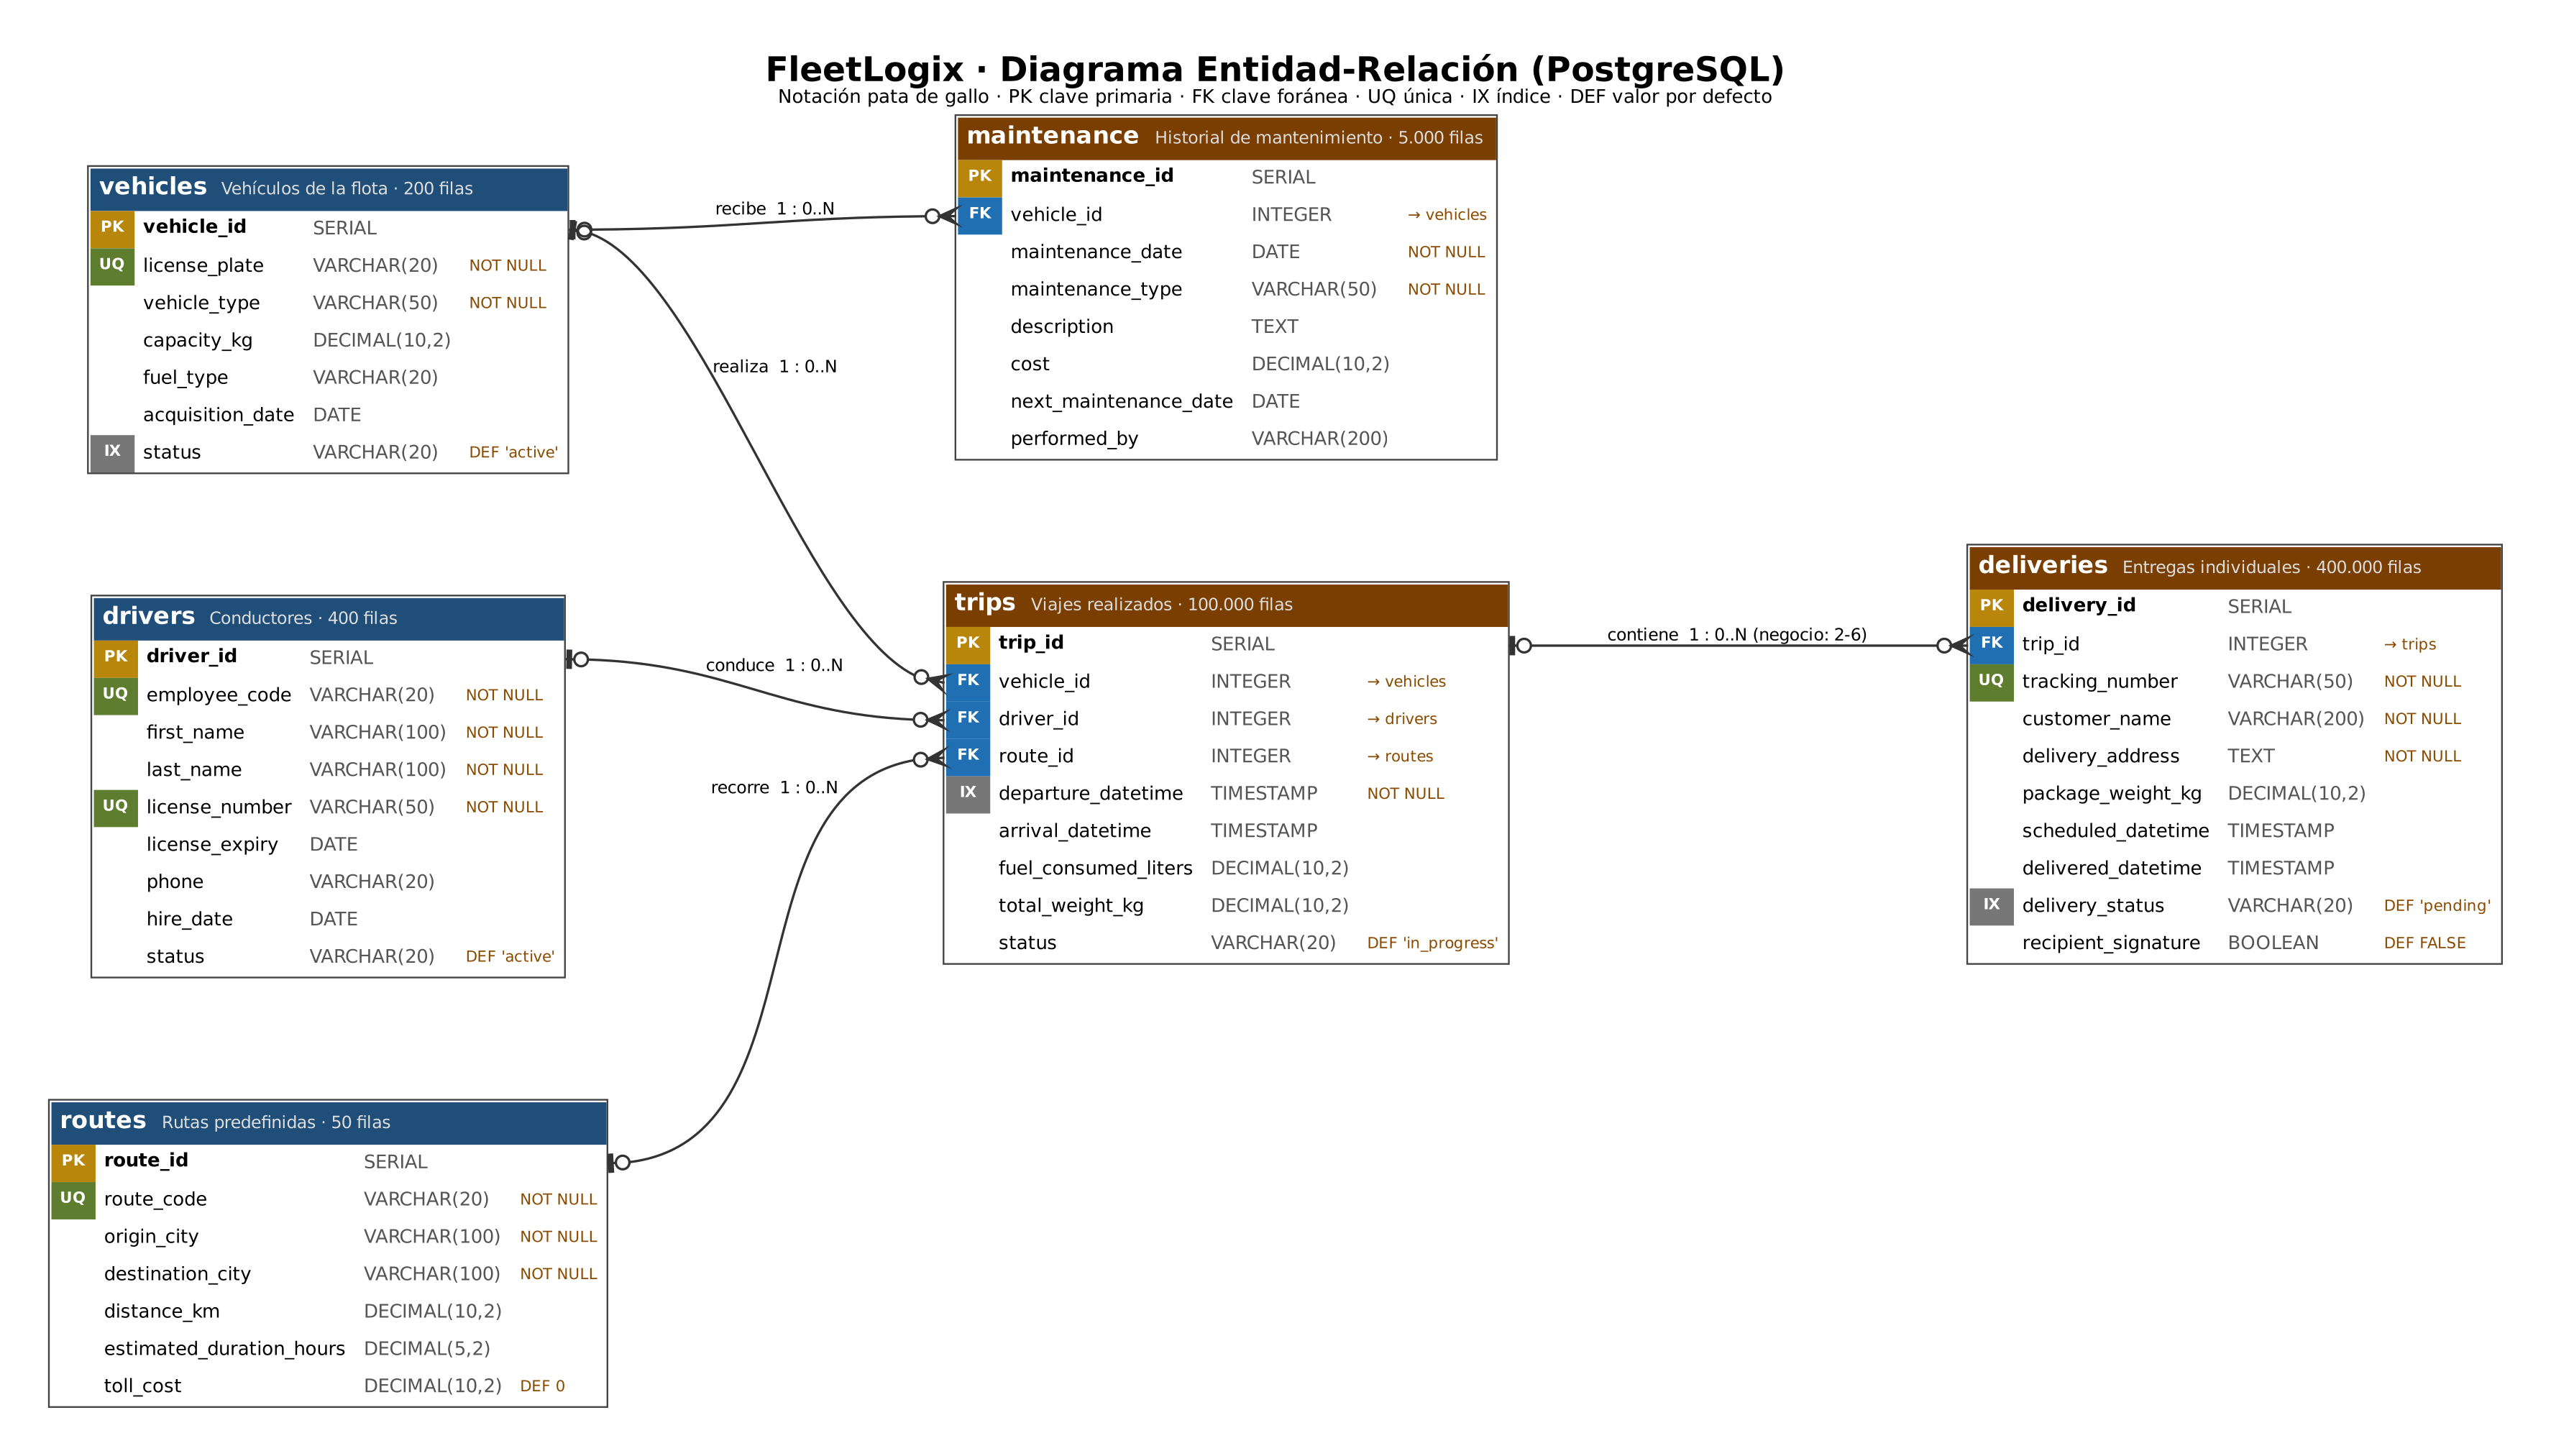

In [3]:
display(Image(filename=str(Path("..") / "3. Documentación" / "diagrama_ER_fleetlogix.png"), width=1100))

### 1.3 Relaciones

| Relación | Cardinalidad | FK | Lectura de negocio |
|---|---|---|---|
| vehicles → trips | 1 : N | `trips.vehicle_id` | Un vehículo realiza muchos viajes; cada viaje usa un vehículo. |
| drivers → trips | 1 : N | `trips.driver_id` | Un conductor hace muchos viajes; cada viaje tiene un conductor. |
| routes → trips | 1 : N | `trips.route_id` | Una ruta se recorre muchas veces; cada viaje sigue una ruta. |
| trips → deliveries | 1 : N (negocio: 2 a 6) | `deliveries.trip_id` | Un viaje lleva varias entregas; cada entrega pertenece a un viaje. |
| vehicles → maintenance | 1 : N | `maintenance.vehicle_id` | Un vehículo recibe muchos servicios. |

**Relaciones implícitas.** `trips` funciona como tabla asociativa: resuelve las relaciones **N:M** entre vehículos, conductores y rutas. Un conductor maneja muchos vehículos a lo largo del tiempo y un vehículo pasa por muchos conductores, pero esa relación no tiene tabla propia: existe solo a través de los viajes.

### 1.4 Constraints

| Tipo | Dónde |
|---|---|
| **PRIMARY KEY** (`SERIAL`) | `vehicle_id`, `driver_id`, `route_id`, `trip_id`, `delivery_id`, `maintenance_id` |
| **UNIQUE** (claves naturales) | `vehicles.license_plate`, `drivers.employee_code`, `drivers.license_number`, `routes.route_code`, `deliveries.tracking_number` |
| **NOT NULL** | placa y tipo de vehículo; legajo, nombre, apellido y licencia del conductor; código, origen y destino de la ruta; `trips.departure_datetime`; tracking, cliente y dirección de la entrega; fecha y tipo de mantenimiento |
| **DEFAULT** | `vehicles.status='active'`, `drivers.status='active'`, `routes.toll_cost=0`, `trips.status='in_progress'`, `deliveries.delivery_status='pending'`, `recipient_signature=FALSE` |
| **FOREIGN KEY** (5) | `trips`→vehicles/drivers/routes, `deliveries`→trips, `maintenance`→vehicles. Sin `ON DELETE`: por defecto es `NO ACTION`, así que no se puede borrar un padre que tenga hijos. |
| **Índices** | 3 provistos (`trips.departure_datetime`, `deliveries.delivery_status`, `vehicles.status`) más los implícitos de cada PK y UNIQUE. PostgreSQL **no crea índices automáticos sobre las FK**: `deliveries.trip_id` (400k filas) se usa en casi todos los joins y no tiene índice. |

Lo verificamos directamente contra el catálogo de PostgreSQL:

In [4]:
import psycopg2
conn = psycopg2.connect(**DB_CONFIG)

constraints = pd.read_sql('''
    SELECT tc.table_name AS tabla, tc.constraint_type AS tipo,
           string_agg(kcu.column_name, ', ') AS columnas,
           MAX(ccu.table_name) FILTER (WHERE tc.constraint_type = 'FOREIGN KEY') AS referencia
    FROM information_schema.table_constraints tc
    JOIN information_schema.key_column_usage kcu
      ON tc.constraint_name = kcu.constraint_name AND tc.table_schema = kcu.table_schema
    LEFT JOIN information_schema.constraint_column_usage ccu
      ON tc.constraint_name = ccu.constraint_name AND tc.table_schema = ccu.table_schema
    WHERE tc.table_schema = 'public'
    GROUP BY tc.table_name, tc.constraint_type, tc.constraint_name
    ORDER BY tabla, tipo''', conn)
constraints

,tabla,tipo,columnas,referencia
0,deliveries,FOREIGN KEY,trip_id,trips
1,deliveries,PRIMARY KEY,delivery_id,NaN
2,deliveries,UNIQUE,tracking_number,NaN
3,drivers,PRIMARY KEY,driver_id,NaN
4,drivers,UNIQUE,employee_code,NaN
5,drivers,UNIQUE,license_number,NaN
6,maintenance,FOREIGN KEY,vehicle_id,vehicles
7,maintenance,PRIMARY KEY,maintenance_id,NaN
8,routes,PRIMARY KEY,route_id,NaN
9,routes,UNIQUE,route_code,NaN


In [5]:
pd.read_sql('''
    SELECT tablename AS tabla, indexname AS indice, indexdef AS definicion
    FROM pg_indexes WHERE schemaname = 'public' ORDER BY tablename, indexname''', conn)

,tabla,indice,definicion
0,deliveries,deliveries_pkey,CREATE UNIQUE INDEX deliveries_pkey ON public....
1,deliveries,deliveries_tracking_number_key,CREATE UNIQUE INDEX deliveries_tracking_number...
2,deliveries,idx_deliveries_status,CREATE INDEX idx_deliveries_status ON public.d...
3,drivers,drivers_employee_code_key,CREATE UNIQUE INDEX drivers_employee_code_key ...
4,drivers,drivers_license_number_key,CREATE UNIQUE INDEX drivers_license_number_key...
5,drivers,drivers_pkey,CREATE UNIQUE INDEX drivers_pkey ON public.dri...
6,maintenance,maintenance_pkey,CREATE UNIQUE INDEX maintenance_pkey ON public...
7,routes,routes_pkey,CREATE UNIQUE INDEX routes_pkey ON public.rout...
8,routes,routes_route_code_key,CREATE UNIQUE INDEX routes_route_code_key ON p...
9,trips,idx_trips_departure,CREATE INDEX idx_trips_departure ON public.tri...


### 1.5 Patrones de negocio implícitos

El esquema no lo dice explícitamente, pero el modelo supone estas reglas, y los datos tienen que respetarlas:

1. **Flujo operativo.** Se asigna vehículo + conductor + ruta → sale el viaje → se hacen 2 a 6 entregas en la ciudad destino → el viaje se cierra. El mantenimiento depende del uso (~1 cada 20 viajes).
2. **Capacidad.** `trips.total_weight_kg ≤ vehicles.capacity_kg`, y la suma de los paquetes de un viaje no puede superar el peso del viaje. Son reglas entre tablas: un `CHECK` no puede expresarlas.
3. **Ciclo de vida por estado.** `in_progress → completed` y `pending → delivered`. La nulabilidad acompaña al estado: un viaje en curso no tiene `arrival_datetime` y una entrega pendiente no tiene `delivered_datetime`.
4. **Consistencia temporal.** `arrival > departure`; las entregas caen dentro de su viaje; nadie maneja antes de ser contratado ni con la licencia vencida; un vehículo no viaja antes de ser comprado.
5. **Recursos no se duplican.** Un conductor o un vehículo no pueden estar en dos viajes a la vez.
6. **Puntualidad como KPI.** La diferencia entre `scheduled_datetime` y `delivered_datetime` mide el nivel de servicio (queries 8 y 10).
7. **Rutas dirigidas con variantes.** Bogotá→Medellín es una ruta distinta de Medellín→Bogotá, y un mismo par de ciudades puede tener varias rutas (vía principal y alternas).
8. **El cliente está embebido como texto.** `customer_name` y `delivery_address` se repiten en cada entrega. No existe una entidad `customers`: un mismo cliente aparece repetido en muchas filas.
9. **Mantenimiento preventivo.** `next_maintenance_date` permite planificar los próximos servicios.

### 1.6 Posibles mejoras (sin modificar la estructura base)

Todas son **aditivas**: no cambian tablas, columnas ni tipos, solo agregan reglas que hoy dependen del código que carga los datos.

| # | Mejora | Por qué |
|---|---|---|
| 1 | `NOT NULL` en las 5 FK | Hoy un viaje o una entrega pueden quedar "huérfanos" con FK nula. |
| 2 | `CHECK` de dominio: `status IN (...)`, `capacity_kg > 0`, `distance_km > 0`, `package_weight_kg > 0`, `origin_city <> destination_city` | Evita valores imposibles o mal escritos (`'Completed'` vs `'completed'`). |
| 3 | `CHECK (arrival_datetime > departure_datetime)` y `CHECK (license_expiry > hire_date)` | Consistencia temporal garantizada por la base. |
| 4 | Índices sobre las FK (`deliveries.trip_id`, `trips.vehicle_id`/`driver_id`/`route_id`, `maintenance.vehicle_id`) | Aceleran los joins entre tablas. |
| 5 | Trigger de capacidad | Valida peso ≤ capacidad, que un `CHECK` no puede hacer porque cruza tablas. |
| 6 | `EXCLUDE USING gist (driver_id WITH =, tsrange(departure, arrival) WITH &&)` | La base misma impide viajes superpuestos de un conductor (extensión `btree_gist`). |
| 7 | `ON DELETE RESTRICT` explícito | Documenta la intención y evita borrados en cascada accidentales. |

Fuera del alcance de este avance, porque sí cambiarían la estructura: una tabla `customers`, `TIMESTAMPTZ` en lugar de `TIMESTAMP`, y columnas de auditoría (`created_at`).

In [6]:
# Ejemplo (NO se aplica): cómo se verían algunas mejoras como DDL aditivo
MEJORAS_SQL = '''
ALTER TABLE trips      ALTER COLUMN vehicle_id SET NOT NULL;
ALTER TABLE trips      ADD CONSTRAINT chk_trips_status CHECK (status IN ('in_progress', 'completed'));
ALTER TABLE trips      ADD CONSTRAINT chk_trips_times  CHECK (arrival_datetime IS NULL OR arrival_datetime > departure_datetime);
ALTER TABLE routes     ADD CONSTRAINT chk_routes_cities CHECK (origin_city <> destination_city);
CREATE INDEX idx_deliveries_trip_id ON deliveries(trip_id);
'''
print(MEJORAS_SQL)


ALTER TABLE trips      ALTER COLUMN vehicle_id SET NOT NULL;
ALTER TABLE trips      ADD CONSTRAINT chk_trips_status CHECK (status IN ('in_progress', 'completed'));
ALTER TABLE trips      ADD CONSTRAINT chk_trips_times  CHECK (arrival_datetime IS NULL OR arrival_datetime > departure_datetime);
ALTER TABLE routes     ADD CONSTRAINT chk_routes_cities CHECK (origin_city <> destination_city);
CREATE INDEX idx_deliveries_trip_id ON deliveries(trip_id);



## 2. Estrategia de generación

El script sigue tres etapas:

1. **Generar en memoria** con pandas, tabla por tabla y en orden de dependencias (maestras → trips → deliveries → maintenance). Los IDs se asignan explícitamente (1..N), así cada FK apunta a un ID que **sabemos que existe** antes de tocar la base.
2. **Cargar con `COPY`** (la vía más rápida de PostgreSQL) en **una sola transacción**. Si algo falla hay `ROLLBACK` y la base nunca queda a medio cargar. Después se sincronizan las secuencias `SERIAL` con `setval`.
3. **Validar con SQL**: 31 chequeos que deben dar 0 violaciones, más un resumen de distribuciones. Todo queda en `data_generation.log` y `generation_summary.json`.

La semilla fija (`SEED = 42`) hace que los datos sean **reproducibles**.

### 2.1 Correcciones a la plantilla original

Partimos de `A1-01_data_generation_estudiantes.py`. Además de completar los `#TO DO#`, corregimos problemas que rompían la coherencia:

| Problema en la plantilla | Consecuencia | Solución |
|---|---|---|
| Generaba **48 rutas** (no 50) pero el log decía 50 | Volumen incorrecto sin aviso | Barranquilla↔Cartagena con 3 variantes → exactamente 50 |
| Placas y licencias aleatorias sin control de duplicados | Un duplicado viola `UNIQUE` y aborta la carga | Generación con conjunto de usados (unicidad garantizada) |
| Vehículo y conductor elegidos al azar | **Viajes superpuestos**: un conductor en dos viajes a la vez | Asignador cronológico con disponibilidad (descanso de 8 h conductor, 1 h vehículo) |
| No miraba fechas de contratación, licencia ni compra | Viajes antes de contratar al conductor o de comprar el vehículo | Solo se asignan recursos vigentes en la fecha del viaje |
| Solo vehículos y conductores `active` *hoy* participaban de los 2 años | Sesgo: los inactivos nunca trabajaron | Los inactivos trabajaron hasta su baja; los vehículos en taller dejan de viajar 10 días antes |
| Consumo 8-15 L/100km para todos | Una moto consumía como un camión | Consumo por tipo (camión grande 28-38, moto 2,5-4), ajustado por terreno y carga |
| Motos asignadas a rutas de 1.000 km | Irreal | Motos solo en rutas ≤ 250 km; preferencia de tipo según distancia |
| Entregas: corte en `> count` y horas ±30 min sin límites | 400.001 entregas; entregas antes de la salida o después de la llegada | Total exacto de 400.000; las entregas siempre caen dentro del viaje |
| Peso mínimo de 0,5 kg aplicado *después* de normalizar | La suma de paquetes podía superar el peso del viaje | Reparto con mínimo incluido: suman exactamente el 95% del viaje |
| Fecha avanzando de a 10 min fijos | 694 días en lugar de 730, sin patrón semanal | Reparto por día con tendencia, día de semana y estacionalidad |
| `execute_batch` fila por fila con commits parciales | Lento y con riesgo de carga parcial | `COPY` en una sola transacción |

### 2.2 Decisiones de realismo

- **Volumen diario:** crecimiento de ~15% anual, menos actividad sábados (70%) y domingos (35%), pico en noviembre y diciembre.
- **Retrasos:** cada viaje tiene una probabilidad de *incidente* (tráfico, clima, bloqueo vial) que sube los viernes, los lunes y en horas pico. Además, 2% de las entregas tienen un problema puntual con el cliente. El resultado: alrededor del 13% de las entregas llegan más de 30 min tarde.
- **Clientes:** cartera de 1.600 clientes por ciudad (80% personas, 20% empresas) con dirección fija. Pocos clientes concentran muchas entregas (distribución tipo Zipf), como en una cartera real.
- **Mantenimiento:** los 5.000 servicios se reparten proporcionalmente a los viajes de cada vehículo y se ubican al completar los viajes N.º 20, 40, 60... El costo escala según el tipo de vehículo.

## 3. Explicación de `generate_trips()` y `_get_hourly_distribution()`

### 3.1 `_get_hourly_distribution()`, la hora de salida

Devuelve un vector de **24 probabilidades**, una por hora del día, que suma 1:

```python
probs = np.ones(24) * 0.02   # base: 2% para todas las horas
probs[6:20]  = 0.06          # 6 a 20 h: jornada laboral
probs[8:12]  = 0.08          # 8 a 12 h: pico de la mañana
probs[14:18] = 0.07          # 14 a 18 h: pico de la tarde
return probs / probs.sum()   # normaliza para que sume 1
```

Los valores son **pesos relativos**: la división final los convierte en probabilidades. Así, una hora pico de la mañana (0,08) es **4 veces más probable** que una hora de madrugada (0,02). Con ese vector, `rng.choice(24, p=...)` sortea la hora de salida de cada viaje. Simula que la operación se concentra en horario laboral pero que también salen viajes de noche, algo habitual en rutas largas.

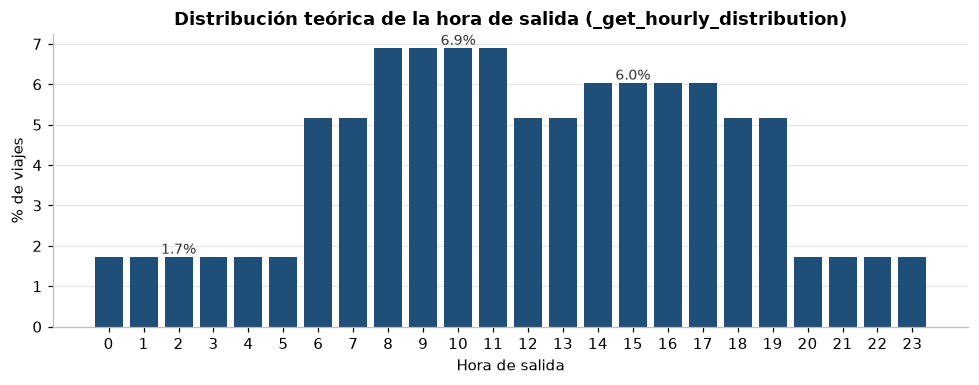

Suma = 1.0000 · pico/madrugada = 4x


In [7]:
gen = dg.DataGenerator(DB_CONFIG)
p = gen._get_hourly_distribution()
fig, ax = plt.subplots()
ax.bar(range(24), p * 100, color=AZUL, width=0.8)
ax.set_xticks(range(24)); ax.set_xlabel("Hora de salida"); ax.set_ylabel("% de viajes")
ax.set_title("Distribución teórica de la hora de salida (_get_hourly_distribution)")
for h in (2, 10, 15):
    ax.annotate(f"{p[h]*100:.1f}%", (h, p[h] * 100), ha="center", va="bottom", fontsize=9, color="#333")
plt.show()
print(f"Suma = {p.sum():.4f} · pico/madrugada = {p[10]/p[2]:.0f}x")

### 3.2 `generate_trips()`, el corazón de la generación

Crea los 100.000 viajes de 2 años y es la función que más reglas de negocio concentra. Paso a paso:

**1. Cuándo sale cada viaje.**
- Cada día del histórico recibe un peso según tendencia × día de semana × mes (`_get_daily_weights`). `multinomial` reparte los 100.000 viajes según esos pesos.
- A cada viaje se le sortea una hora con `_get_hourly_distribution()` y un minuto al azar.
- Las salidas se ordenan cronológicamente.

**2. Cuántas entregas tendrá cada viaje.** Se sortea entre 2 y 6 con probabilidades 10/20/40/20/10% (moda 4, media 4,0). Después se ajusta para que el total sea **exactamente 400.000**.

**3. Asignación de recursos, en orden cronológico.** Para cada viaje se sortea una ruta y se arman dos máscaras booleanas con numpy:
- **Vehículos elegibles:** ya comprados, libres (su viaje anterior terminó hace más de 1 h) y aptos para la distancia (motos solo en rutas cortas). Si el vehículo hoy está en taller, no tiene viajes en los últimos 10 días.
- **Conductores elegibles:** ya contratados, con licencia vigente durante el viaje, sin haberse ido de la empresa y con 8 h de descanso desde su viaje anterior.
- Entre los vehículos elegibles se elige con **preferencia por tipo**: en rutas cortas pesan más vans y motos; en largas, los camiones. El conductor se elige al azar entre los elegibles.
- Si no hay ninguno libre, la salida **se demora** hasta que se libere el primero (~1,3% de los viajes). Así nunca hay superposición.

**4. Horarios programados y reales.**
- *Programado*: salida + duración estimada de la ruta + una ventana por parada (25 a 60 min según el tipo de vehículo).
- *Real*: programado + demora del viaje + ruido por entrega. La demora puede venir de un incidente (45-150 min, más probable viernes, lunes y horas pico) o de una variación normal (±20 min).
- La **llegada** es la última entrega + 10-30 min de cierre. Por construcción, `arrival > departure` y todas las entregas quedan dentro del viaje.

**5. Carga y combustible.**
- Peso del viaje: 40-90% de la capacidad del vehículo.
- Consumo: distancia × L/100km del tipo de vehículo × factor de terreno de la ruta × ajuste por carga.

**6. Estado.** Si la llegada ya pasó el viaje es `completed`; si no, queda `in_progress`, sin `arrival_datetime` ni consumo final, porque todavía no se conocen.

Al terminar, cada recurso queda **ocupado** hasta su llegada más el descanso. Esa disponibilidad es la que consulta el viaje siguiente.

## 4. Ejecución

Cada paso genera un DataFrame en memoria. Vemos una muestra de cada tabla antes de cargarla.

In [8]:
vehicles = gen.generate_vehicles()
drivers = gen.generate_drivers()
routes = gen.generate_routes()
display(vehicles.head(), drivers.drop(columns="_end_date").head(), routes.drop(columns="_terrain").head())

2026-10-15 12:43:39,378 - INFO - Generando 200 vehículos...
2026-10-15 12:43:39,393 - INFO -   200 vehículos generados {'Camión Mediano': 63, 'Van': 61, 'Camión Grande': 60, 'Motocicleta': 16}
2026-10-15 12:43:39,394 - INFO - Generando 400 conductores...
2026-10-15 12:43:39,422 - INFO -   400 conductores generados (377 activos)
2026-10-15 12:43:39,423 - INFO - Generando 50 rutas...
2026-10-15 12:43:39,424 - INFO -   50 rutas generadas


,vehicle_id,license_plate,vehicle_type,capacity_kg,fuel_type,acquisition_date,status
0,1,ZUI974,Van,1500.0,gasolina,2024-04-13,active
1,2,MNL229,Camión Mediano,3000.0,diesel,2025-05-23,active
2,3,YAE306,Van,1500.0,gasolina,2025-10-08,maintenance
3,4,HDA709,Van,1500.0,gasolina,2023-12-15,active
4,5,ZDH555,Camión Grande,5000.0,diesel,2024-12-25,active


,driver_id,employee_code,first_name,last_name,license_number,license_expiry,phone,hire_date,status
0,1,EMP0001,Jorge,Marín,1473183912,2028-02-04,3407384435,2022-12-15,active
1,2,EMP0002,María,Rojas,9509679019,2029-10-13,3574079915,2023-01-18,active
2,3,EMP0003,Esperanza,Ortega,4532362608,2027-08-03,3200584280,2022-06-19,active
3,4,EMP0004,Inés,Galeano,9315103604,2027-04-19,3567250511,2023-04-05,active
4,5,EMP0005,Felipe,Rosero,6210797722,2029-08-15,3842865643,2023-05-07,inactive


,route_id,route_code,origin_city,destination_city,distance_km,estimated_duration_hours,toll_cost
0,1,R001,Bogotá,Medellín,445.48,6.70,60000.0
1,2,R002,Bogotá,Medellín,431.68,6.64,60000.0
2,3,R003,Bogotá,Medellín,436.92,6.94,60000.0
3,4,R004,Bogotá,Cali,503.43,6.99,75000.0
4,5,R005,Bogotá,Cali,435.51,5.90,60000.0


In [9]:
%%time
trips = gen.generate_trips()
trips.head()

2026-10-15 12:43:43,511 - INFO - Generando 100000 viajes...
2026-10-15 12:43:46,014 - INFO -   100000 viajes generados | completed=99981 in_progress=19 | salidas demoradas por falta de recursos=1270
CPU times: user 2.46 s, sys: 32.2 ms, total: 2.5 s
Wall time: 2.5 s


,trip_id,vehicle_id,driver_id,route_id,departure_datetime,arrival_datetime,fuel_consumed_liters,total_weight_kg,status
0,1,139,103,43,2024-10-15 00:42:00,2024-10-15 18:18:00,119.79,747.74,completed
1,2,124,115,31,2024-10-15 00:52:00,2024-10-15 17:25:00,207.56,2078.86,completed
2,3,69,95,32,2024-10-15 01:25:00,2024-10-15 21:16:00,379.98,3471.48,completed
3,4,9,116,13,2024-10-15 01:26:00,2024-10-15 08:12:00,138.82,3875.11,completed
4,5,147,163,32,2024-10-15 01:27:00,2024-10-15 19:58:00,202.34,1313.45,completed


In [10]:
%%time
deliveries = gen.generate_deliveries()
deliveries.drop(columns="_seq").head()

2026-10-15 12:43:50,242 - INFO - Generando 400000 entregas...
2026-10-15 12:43:50,817 - INFO -   400000 entregas generadas | delivered=399964 pending=36
CPU times: user 533 ms, sys: 34.3 ms, total: 567 ms
Wall time: 576 ms


,delivery_id,trip_id,tracking_number,customer_name,delivery_address,package_weight_kg,scheduled_datetime,delivered_datetime,delivery_status,recipient_signature
0,1,1,FL202400000001,Marcela Montoya,"Carrera 97 # 29-5 Este, Bogotá",100.73,2024-10-15 16:13:00,2024-10-15 16:22:00,delivered,True
1,2,1,FL202400000002,Ferretería Prieto S.A.S.,"Calle 35 # 1-80 Sur, Bogotá",304.31,2024-10-15 16:48:00,2024-10-15 16:47:00,delivered,True
2,3,1,FL202400000003,Comercializadora Bohórquez Ltda.,"Av. carrera 117 # 74-25 Sur, Bogotá",258.07,2024-10-15 17:23:00,2024-10-15 17:32:00,delivered,True
3,4,1,FL202400000004,Distribuciones Mesa S.A.,"Calle 49 # 9-4 Este, Bogotá",47.23,2024-10-15 17:58:00,2024-10-15 18:04:00,delivered,True
4,5,2,FL202400000005,Nidia Alexandra Arévalo,"Avenida carrera 9ª # 5-1, Bogotá",1558.67,2024-10-15 15:28:00,2024-10-15 15:30:00,delivered,True


In [11]:
maintenance = gen.generate_maintenance()
maintenance.head()

2026-10-15 12:43:54,701 - INFO - Generando 5000 registros de mantenimiento...
2026-10-15 12:43:54,960 - INFO -   5000 mantenimientos generados (200 vehículos)


,maintenance_id,vehicle_id,maintenance_date,maintenance_type,description,cost,next_maintenance_date,performed_by
0,1,41,2024-10-30,Cambio de llantas,Cambio de llantas - vehículo XGF324 (Camión Me...,587995.22,2025-01-28,Deisy Valencia (Autocentro Costa)
1,2,95,2024-10-30,Mantenimiento general,Mantenimiento general - vehículo WQD209 (Camió...,459229.40,2024-12-14,Martha Ariza (Diesel Andino)
2,3,127,2024-10-30,Cambio de aceite,Cambio de aceite - vehículo JZP512 (Camión Med...,190223.45,2024-11-29,Luz Montoya (Taller Pacífico)
3,4,70,2024-10-31,Cambio de llantas,Cambio de llantas - vehículo SDY962 (Camión Me...,487548.96,2025-01-29,Yuliana Pérez (Taller Central)
4,5,140,2024-10-31,Revisión de motor,Revisión de motor - vehículo PIX132 (Camión Gr...,890625.57,2024-12-30,Ángela Pacheco (Taller Pacífico)


### 4.1 Carga en PostgreSQL

`load_all()` vacía las tablas (`TRUNCATE ... RESTART IDENTITY`), carga las 6 con `COPY` en una transacción y sincroniza las secuencias. **Se puede re-ejecutar** sin generar duplicados.

In [12]:
%%time
gen.connect()
gen.load_all(reset=True)

2026-10-15 12:43:59,272 - INFO - Conexión exitosa a PostgreSQL (localhost/fleetlogix)
2026-10-15 12:43:59,272 - INFO - Cargando datos en PostgreSQL con COPY...
2026-10-15 12:43:59,299 - INFO -   vehicles           200 registros cargados
2026-10-15 12:43:59,305 - INFO -   drivers            400 registros cargados
2026-10-15 12:43:59,307 - INFO -   routes              50 registros cargados
2026-10-15 12:44:00,273 - INFO -   trips          100,000 registros cargados
2026-10-15 12:44:02,734 - INFO -   deliveries     400,000 registros cargados
2026-10-15 12:44:02,782 - INFO -   maintenance      5,000 registros cargados
2026-10-15 12:44:02,972 - INFO - Carga confirmada (COMMIT)
CPU times: user 937 ms, sys: 79.7 ms, total: 1.02 s
Wall time: 3.71 s


## 5. Control de calidad

### 5.1 Validaciones: 31 chequeos, todos deben dar 0 violaciones

Cubren volúmenes exactos, integridad referencial, consistencia temporal (arrival > departure, entregas dentro del viaje, contrataciones, licencias, compras), horarios sin superposición, capacidad, pesos y reglas de negocio.

In [13]:
ok, checks = gen.run_validations()
checks_df = pd.DataFrame(checks)
checks_df["categoría"] = checks_df["check"].str.split(" - ").str[0]
print(f"Validaciones OK: {checks_df['ok'].sum()} de {len(checks_df)}  ->  {'TODO OK' if ok else 'HAY FALLAS'}")
checks_df[["categoría", "check", "violations", "ok"]]

2026-10-15 12:45:36,150 - INFO - VALIDANDO CALIDAD DE DATOS...
2026-10-15 12:45:36,153 - INFO -   [OK] Volumen - vehicles != 200: 0
2026-10-15 12:45:36,155 - INFO -   [OK] Volumen - drivers != 400: 0
2026-10-15 12:45:36,156 - INFO -   [OK] Volumen - routes != 50: 0
2026-10-15 12:45:36,165 - INFO -   [OK] Volumen - trips != 100000: 0
2026-10-15 12:45:36,182 - INFO -   [OK] Volumen - deliveries != 400000: 0
2026-10-15 12:45:36,185 - INFO -   [OK] Volumen - maintenance != 5000: 0
2026-10-15 12:45:36,192 - INFO -   [OK] Integridad - trips sin vehículo válido: 0
2026-10-15 12:45:36,199 - INFO -   [OK] Integridad - trips sin conductor válido: 0
2026-10-15 12:45:36,205 - INFO -   [OK] Integridad - trips sin ruta válida: 0
2026-10-15 12:45:36,223 - INFO -   [OK] Integridad - deliveries sin trip válido: 0
2026-10-15 12:45:36,224 - INFO -   [OK] Integridad - maintenance sin vehículo válido: 0
2026-10-15 12:45:36,228 - INFO -   [OK] Temporal - trips con arrival <= departure: 0
2026-10-15 12:45:36

,categoría,check,violations,ok
0,Volumen,Volumen - vehicles != 200,0,True
1,Volumen,Volumen - drivers != 400,0,True
2,Volumen,Volumen - routes != 50,0,True
3,Volumen,Volumen - trips != 100000,0,True
4,Volumen,Volumen - deliveries != 400000,0,True
5,Volumen,Volumen - maintenance != 5000,0,True
6,Integridad,Integridad - trips sin vehículo válido,0,True
7,Integridad,Integridad - trips sin conductor válido,0,True
8,Integridad,Integridad - trips sin ruta válida,0,True
9,Integridad,Integridad - deliveries sin trip válido,0,True


### 5.2 Volúmenes cargados y resumen (`generation_summary.json`)

In [14]:
summary = gen.generate_summary_report()
pd.Series(summary["table_counts"], name="registros").to_frame().assign(
    registros=lambda d: d["registros"].map("{:,}".format))

2026-10-15 12:45:41,938 - INFO - RESUMEN DE GENERACIÓN DE DATOS
2026-10-15 12:45:41,938 - INFO - ==================================================
2026-10-15 12:45:41,940 - INFO -   vehicles           200 registros
2026-10-15 12:45:41,941 - INFO -   drivers            400 registros
2026-10-15 12:45:41,942 - INFO -   routes              50 registros
2026-10-15 12:45:41,949 - INFO -   trips          100,000 registros
2026-10-15 12:45:41,972 - INFO -   deliveries     400,000 registros
2026-10-15 12:45:41,977 - INFO -   maintenance      5,000 registros
2026-10-15 12:45:41,979 - INFO -   TOTAL          505,650 registros
2026-10-15 12:45:41,980 - INFO - VALIDANDO CALIDAD DE DATOS...
2026-10-15 12:45:41,983 - INFO -   [OK] Volumen - vehicles != 200: 0
2026-10-15 12:45:41,984 - INFO -   [OK] Volumen - drivers != 400: 0
2026-10-15 12:45:41,986 - INFO -   [OK] Volumen - routes != 50: 0
2026-10-15 12:45:41,993 - INFO -   [OK] Volumen - trips != 100000: 0
2026-10-15 12:45:42,005 - INFO -   [OK] V

,registros
vehicles,200
drivers,400
routes,50
trips,"100,000"
deliveries,"400,000"
maintenance,"5,000"


### 5.3 Distribuciones: ¿los datos se parecen a una operación real?

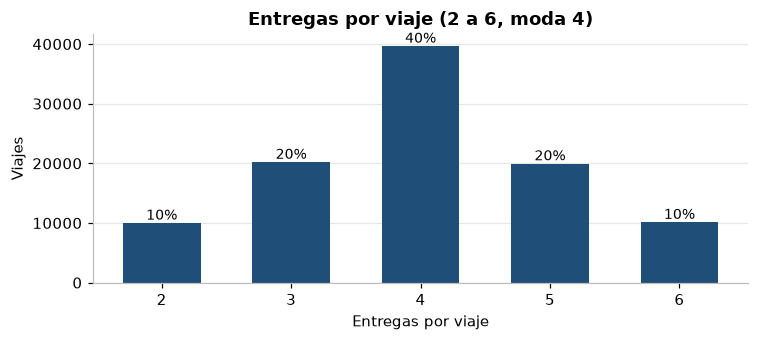

In [15]:
q = lambda sql: pd.read_sql(sql, gen.connection)

ent = q("SELECT n, COUNT(*) viajes FROM (SELECT trip_id, COUNT(*) n FROM deliveries GROUP BY trip_id) x GROUP BY n ORDER BY n")
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(ent["n"], ent["viajes"], color=AZUL, width=0.6)
for x, y in zip(ent["n"], ent["viajes"]):
    ax.annotate(f"{y/ent['viajes'].sum():.0%}", (x, y), ha="center", va="bottom", fontsize=9)
ax.set_xlabel("Entregas por viaje"); ax.set_ylabel("Viajes"); ax.set_title("Entregas por viaje (2 a 6, moda 4)")
plt.show()

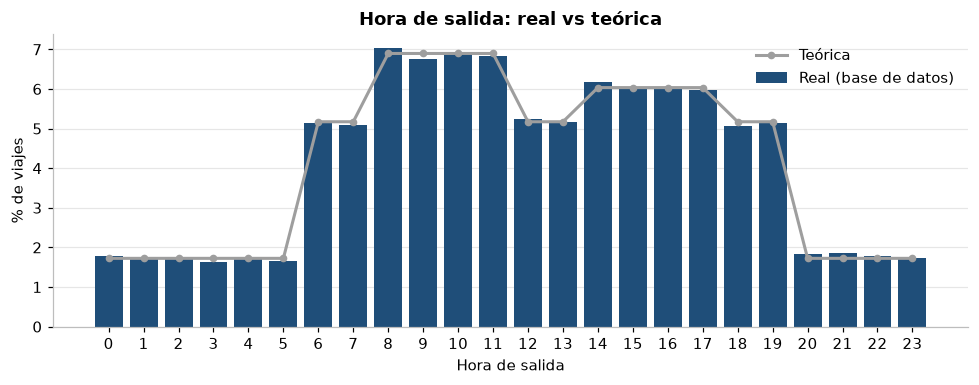

In [16]:
hora = q("SELECT EXTRACT(HOUR FROM departure_datetime)::int h, COUNT(*) n FROM trips GROUP BY 1 ORDER BY 1")
fig, ax = plt.subplots()
ax.bar(hora["h"], hora["n"] / hora["n"].sum() * 100, color=AZUL, width=0.8, label="Real (base de datos)")
ax.plot(range(24), gen._get_hourly_distribution() * 100, color=GRIS, lw=2, marker="o", ms=4, label="Teórica")
ax.set_xticks(range(24)); ax.set_xlabel("Hora de salida"); ax.set_ylabel("% de viajes")
ax.set_title("Hora de salida: real vs teórica"); ax.legend(frameon=False)
plt.show()

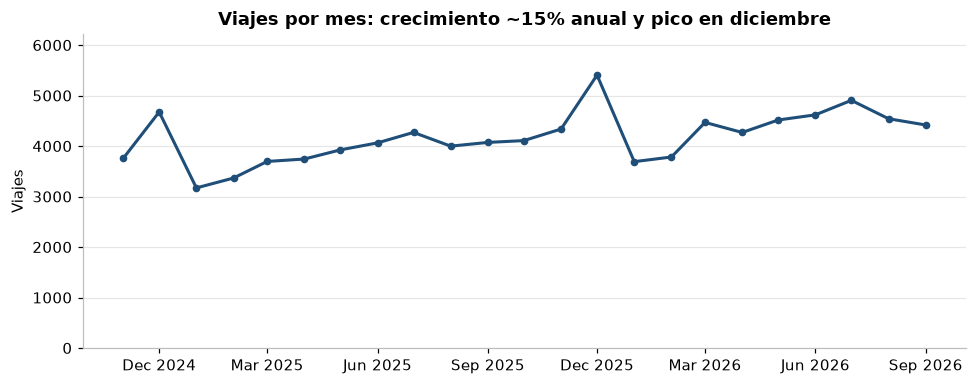

In [17]:
mes = q("SELECT DATE_TRUNC('month', departure_datetime) mes, COUNT(*) viajes FROM trips GROUP BY 1 ORDER BY 1")
mes["mes"] = pd.to_datetime(mes["mes"])
mes = mes.iloc[1:-1]  # se excluyen el primer y el último mes, que están incompletos
fig, ax = plt.subplots()
ax.plot(mes["mes"], mes["viajes"], color=AZUL, lw=2, marker="o", ms=4)
ax.set_ylabel("Viajes"); ax.set_title("Viajes por mes: crecimiento ~15% anual y pico en diciembre")
ax.set_ylim(0, mes["viajes"].max() * 1.15)
import matplotlib.dates as mdates
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.show()

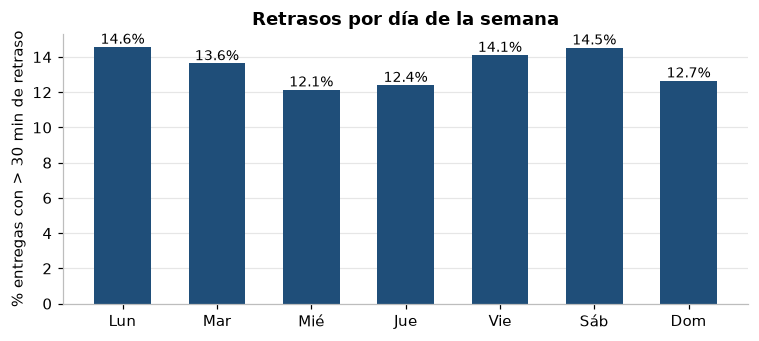

In [19]:
ret = q('''
    SELECT EXTRACT(ISODOW FROM scheduled_datetime)::int dow,
           100.0 * AVG((delivered_datetime > scheduled_datetime + INTERVAL '30 minutes')::int) pct
    FROM deliveries WHERE delivery_status = 'delivered' GROUP BY 1 ORDER BY 1''')
dias = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar([dias[d - 1] for d in ret["dow"]], ret["pct"], color=AZUL, width=0.6)
for i, v in enumerate(ret["pct"]):
    ax.annotate(f"{v:.1f}%", (i, v), ha="center", va="bottom", fontsize=9)
ax.set_ylabel("% entregas con > 30 min de retraso"); ax.set_title("Retrasos por día de la semana")
plt.show()

In [18]:
# Consumo por tipo de vehículo: cada tipo debe quedar en su rango
q('''
    SELECT v.vehicle_type AS tipo, COUNT(DISTINCT v.vehicle_id) AS vehiculos, COUNT(t.trip_id) AS viajes,
           ROUND(AVG(t.fuel_consumed_liters / r.distance_km * 100), 1) AS l_100km,
           ROUND(AVG(t.total_weight_kg / v.capacity_kg) * 100, 1) AS ocupacion_pct,
           MAX(r.distance_km) AS ruta_mas_larga_km
    FROM vehicles v
    JOIN trips t ON t.vehicle_id = v.vehicle_id AND t.status = 'completed'
    JOIN routes r ON r.route_id = t.route_id
    GROUP BY v.vehicle_type ORDER BY l_100km DESC''')

,tipo,vehiculos,viajes,l_100km,ocupacion_pct,ruta_mas_larga_km
0,Camión Grande,60,31842,35.3,64.9,1231.49
1,Camión Mediano,63,33481,23.5,65.0,1231.49
2,Van,61,30563,12.9,64.9,1231.49
3,Motocicleta,16,4095,3.5,64.6,130.26


In [20]:
# Estados y carga de trabajo por conductor
display(q('''SELECT 'trips' tabla, status estado, COUNT(*) FROM trips GROUP BY 2
             UNION ALL SELECT 'deliveries', delivery_status, COUNT(*) FROM deliveries GROUP BY 2
             ORDER BY 1, 3 DESC'''))
q('''SELECT MIN(n) min_viajes, ROUND(AVG(n)) promedio, MAX(n) max_viajes
     FROM (SELECT driver_id, COUNT(*) n FROM trips GROUP BY 1) x''')

,tabla,estado,count
0,deliveries,delivered,399964
1,deliveries,pending,36
2,trips,completed,99981
3,trips,in_progress,19


,min_viajes,promedio,max_viajes
0,5,254.0,357


### 5.4 Logs de carga

In [21]:
print("".join(open("data_generation.log", encoding="utf-8").readlines()[-45:]))

2026-10-15 12:45:42,367 - INFO -   [OK] Negocio - viajes con menos de 2 o más de 6 entregas: 0
2026-10-15 12:45:42,396 - INFO -   [OK] Negocio - entregas en ciudad distinta al destino: 0
2026-10-15 12:45:42,406 - INFO -   [OK] Negocio - firma sin entrega: 0
2026-10-15 12:45:42,406 - INFO -   [OK] Negocio - origen igual a destino: 0
2026-10-15 12:45:42,420 - INFO -   [OK] Negocio - valores no positivos: 0
2026-10-15 12:45:42,421 - INFO -   [OK] Negocio - tracking number vacío: 0
2026-10-15 12:45:42,421 - INFO - DISTRIBUCIONES...
2026-10-15 12:45:42,472 - INFO -   Entregas por viaje:
 entregas_por_viaje  viajes  pct
                  2   10012 10.0
                  3   20215 20.2
                  4   39672 39.7
                  5   19963 20.0
                  6   10138 10.1
2026-10-15 12:45:42,518 - INFO -   Flota por tipo:
  vehicle_type  vehiculos  viajes  l_100km
Camión Mediano         63   33488     23.5
           Van         61   30566     12.9
 Camión Grande         60   31851

In [22]:
gen.close()
conn.close()

2026-10-15 12:46:23,141 - INFO - Conexión cerrada


## 6. Conclusiones

- **Modelo.** Seis tablas organizadas alrededor de `trips`, que resuelve la relación N:M entre vehículos, conductores y rutas. Las FK son nulables y no están indexadas, y varias reglas del negocio (capacidad, horarios, estados) **dependen de la aplicación** y no de la base. Proponemos 7 mejoras aditivas.
- **Datos.** 505.650 registros cargados en una transacción con `COPY`, en menos de un minuto. Las 31 validaciones dan **0 violaciones**: integridad referencial completa, `arrival > departure`, entregas dentro de su viaje, sin superposición de horarios, sin exceso de capacidad.
- **Realismo.** Los datos reproducen patrones reales: estacionalidad y crecimiento, horas pico, más retrasos los viernes y lunes, consumo y costo de mantenimiento diferenciados por tipo de vehículo, y clientes recurrentes.
- **Corregimos la plantilla** en 11 puntos que comprometían la coherencia (sección 2.1).